# 3. Evaluation, error analysis and over/underfitting diagnostics

The test window (last 20%) was read **once**, by `train.py`, after the model and its hyper-parameters were locked. Everything below is read from `metrics.json` / `diagnostics.json`, or recomputed from the saved models.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1]              # notebooks live in ml/notebooks
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "ml"))
import common as C, model_zoo as Z
from common import cfg
from data_loader import load_plazas, load_transactions, validate
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
plazas = load_plazas()
df = load_transactions(plazas=plazas)              # validated, time-ordered, clean index
splits = C.split_time(df)
specs = C.detector_specs(plazas)
import joblib
from sklearn.metrics import precision_recall_curve
M = json.loads(cfg.METRICS_JSON.read_text()); DG = json.loads(cfg.DIAGNOSTICS_JSON.read_text())
calib = joblib.load(cfg.CALIBRATION); test = splits["test"]

## Test results against the baselines

In [2]:
rows = []
for name, m in M["models"].items():
    if name == "rules": continue
    for lab, key in [("Selected model, calibrated (p>=0.5)", "calibrated_p_ge_0.5"), ("Single tuned threshold / fixed rule", "baseline_simple_rule"), ("Context rule (same context as the model)", "baseline_context_rule"), ("Default Isolation Forest threshold", "baseline_iforest_default_threshold")]:
        if key in m: r = m[key]; rows.append({"detector": name, "variant": lab, "precision": r["precision"], "recall": r["recall"], "f1": r["f1"], "FP": r["fp"]})
pd.DataFrame(rows).set_index(["detector", "variant"])

precision  recall  \
detector     variant                                                       
api_flood    Selected model, calibrated (p>=0.5)          0.9689  0.9478   
             Single tuned threshold / fixed rule          0.8231  0.9913   
             Default Isolation Forest threshold           0.1777  1.0000   
fare_anomaly Selected model, calibrated (p>=0.5)          0.9962  0.9220   
             Single tuned threshold / fixed rule          0.1388  1.0000   
             Context rule (same context as the model)     0.7084  0.9823   
             Default Isolation Forest threshold           0.1377  1.0000   

                                                           f1    FP  
detector     variant                                                 
api_flood    Selected model, calibrated (p>=0.5)       0.9582     7  
             Single tuned threshold / fixed rule       0.8994    49  
             Default Isolation Forest threshold        0.3018  1064  
fare_anomaly Selected model, calibrated (p>=0.5)       0.9576     1  
             Single tuned threshold / fixed rule       0.2437  1750  
             Context rule (same context as the model)  0.8232   114  
             Default Isolation Forest threshold        0.2421  1766

In [3]:
for name, m in M["models"].items():
    if name == "rules": continue
    print(f"{name}: PR-AUC {m['pr_auc']} ROC-AUC {m['roc_auc']} | precision at 1% / 0.1% prevalence: {m['precision_at_prevalence']['1pct']} / {m['precision_at_prevalence']['0.1pct']}", "| events:", m.get("event_level"))
print(); print(pd.DataFrame(M["models"]["rules"]).T)

api_flood: PR-AUC 0.9905 ROC-AUC 0.9995 | precision at 1% / 0.1% prevalence: 0.9254 / 0.5513 | events: {'events': 30, 'detected': 30, 'recall': 1.0}
fare_anomaly: PR-AUC 0.9796 ROC-AUC 0.9984 | precision at 1% / 0.1% prevalence: 0.9836 / 0.856 | events: None

                  flagged  labelled  true_positives  precision  recall  \
cloned_tag         1083.0    1000.0          1000.0     0.9234     1.0   
class_mismatch       55.0      55.0            55.0     1.0000     1.0   
duplicate_charge   1500.0    1500.0          1500.0     1.0000     1.0   

                  probability_used  
cloned_tag                  0.9989  
class_mismatch              0.9825  
duplicate_charge            0.9993  


## Precision-recall curves on the test window

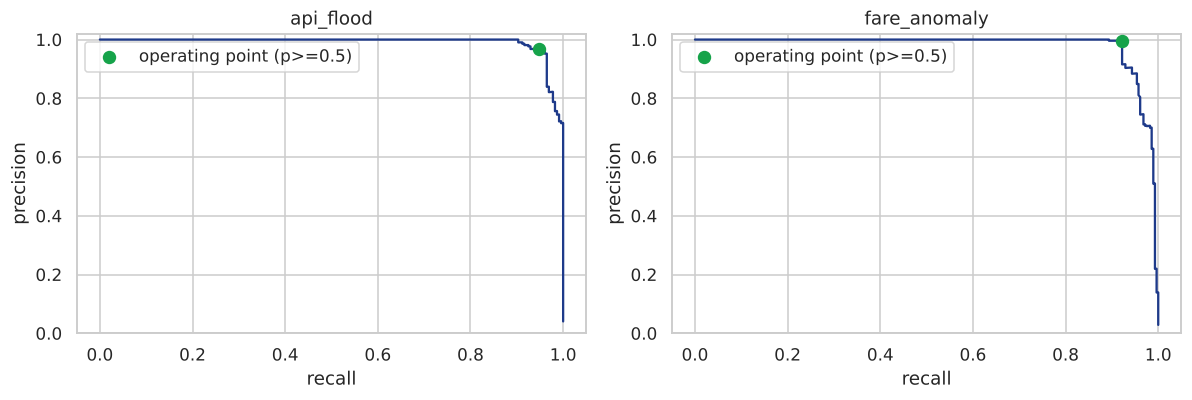

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (name, spec) in zip(ax, specs.items()):
    model, iso = joblib.load(spec["model_path"]), calib["calibrators"][name]; pr = C.predict(spec, model, iso, test); y = C.labels(test, spec); g = pr["gate"]
    p, r, _ = precision_recall_curve(y[g], pr["score"][g]); a.plot(r, p, color="#1E3A8A"); mm = M["models"][name]["calibrated_p_ge_0.5"]
    a.scatter([mm["recall"]], [mm["precision"]], color="#16A34A", s=60, zorder=3, label="operating point (p>=0.5)"); a.set_xlabel("recall"); a.set_ylabel("precision"); a.set_title(name); a.legend(); a.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

## Calibration: does a predicted 80% mean 80%?

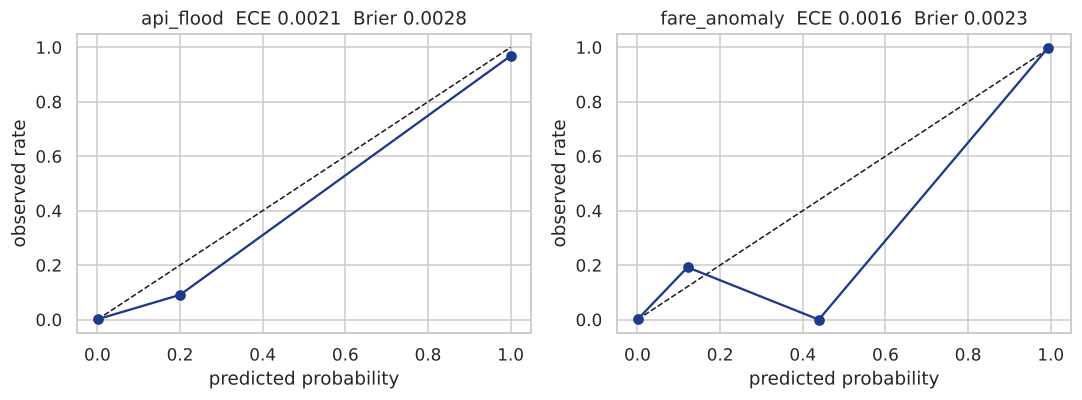

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (name, e) in zip(ax, DG["detectors"].items()):
    rel = e["data"]["calibration"]["reliability"]; a.plot([0, 1], [0, 1], "k--", lw=1); a.plot([r["predicted"] for r in rel], [r["observed"] for r in rel], "o-", color="#1E3A8A")
    a.set_title(f"{name}  ECE {e['data']['calibration']['ece']}  Brier {e['data']['calibration']['brier']}"); a.set_xlabel("predicted probability"); a.set_ylabel("observed rate")
plt.tight_layout(); plt.show()

# Over- and underfitting

| Check | Question | Pass rule |
|---|---|---|
| train vs test gap | does it do better on rows it was fitted on? | gap <= 0.05 (PR-AUC and F1) |
| fresh worlds | does it hold on brand-new datasets, never refitted? | F1 within 0.05 of test |
| headroom | is a higher-capacity supervised model far better? | <= 0.05 PR-AUC |
| beats baselines | does it beat the best simple rule? | test F1 > baseline F1 |
| capacity | would more trees help? | gain <= 0.01 PR-AUC |

Plus two stability views (learning curve, rolling windows) and **positive controls** that prove the checks can fail.

In [6]:
vt = []
for name, e in DG["detectors"].items():
    vt.append({"detector": name, "verdict": e["verdict"].upper(), **{k: f"{v['value']:+.3f} ({'ok' if v['pass'] else 'FAIL'})" for k, v in e["checks"].items()}})
pd.DataFrame(vt).set_index("detector")

,verdict,train_test_gap,fresh_world_f1,headroom,beats_baselines,capacity_saturated
detector,,,,,,
api_flood,GOOD FIT,+0.008 (ok),-0.004 (ok),+0.001 (ok),+0.059 (ok),+0.000 (ok)
fare_anomaly,GOOD FIT,+0.014 (ok),-0.011 (ok),+0.026 (ok),+0.134 (ok),+0.007 (ok)


## Learning curves: train and validation should converge, both high
Flat, high lines mean the model has already learned what the data can teach (not underfit: they are high). For floods train and validation overlap (not overfit). For fares a small gap opens as data grows (train 0.991, validation 0.982): worth watching, but well inside the 0.05 limit. A widening gap beyond that would signal overfitting; two low lines would signal underfitting.

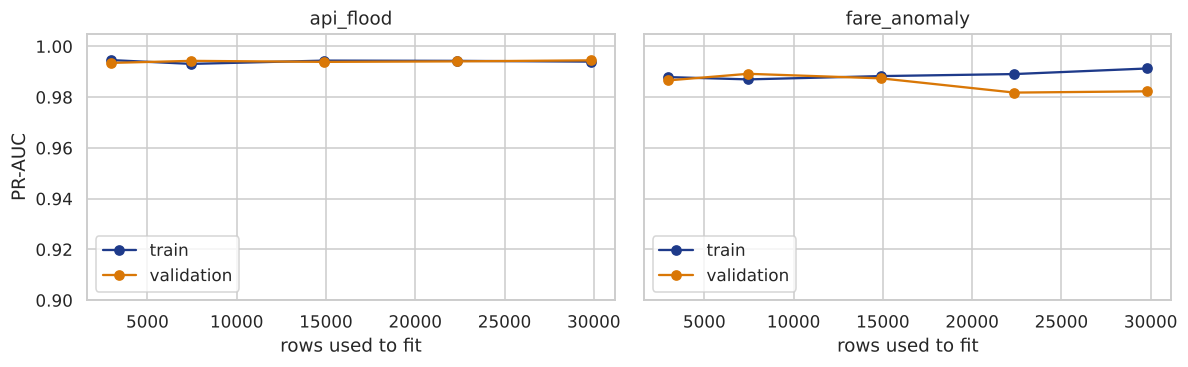

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (name, e) in zip(ax, DG["detectors"].items()):
    lc = e["data"]["learning_curve"]; x = [r["rows"] for r in lc]
    a.plot(x, [r["train_pr_auc"] for r in lc], "o-", color="#1E3A8A", label="train"); a.plot(x, [r["val_pr_auc"] for r in lc], "o-", color="#D97706", label="validation")
    a.set_title(name); a.set_xlabel("rows used to fit"); a.set_ylim(0.9, 1.005); a.legend()
ax[0].set_ylabel("PR-AUC"); plt.tight_layout(); plt.show()

## Capacity: too little capacity underfits; the choice should sit on the plateau

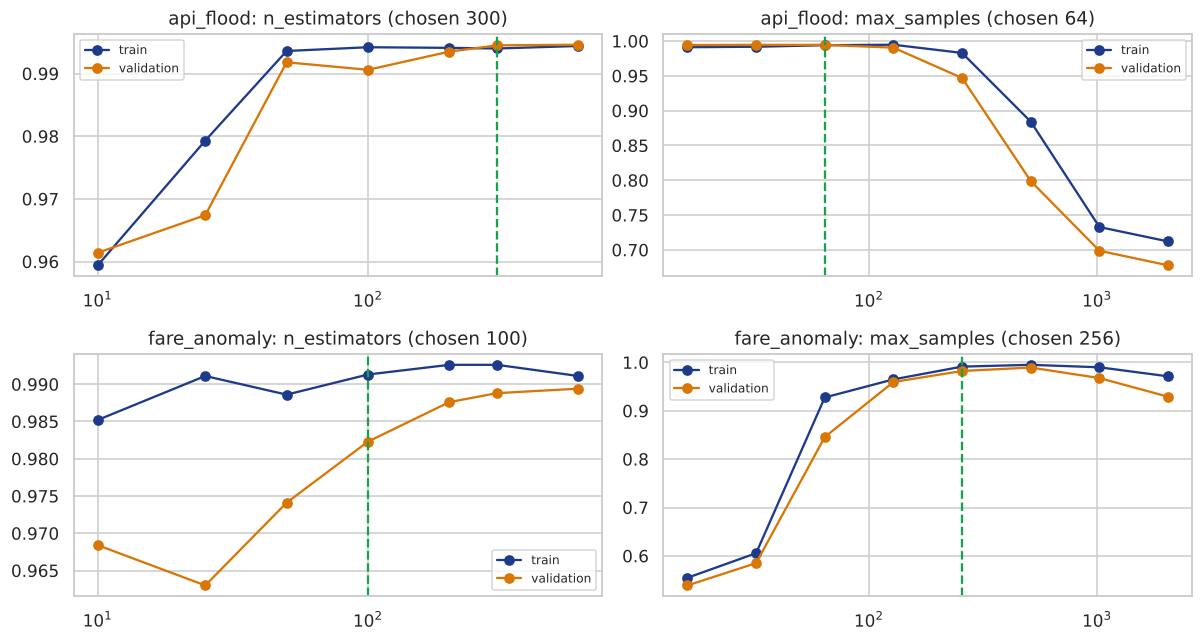

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for i, (name, e) in enumerate(DG["detectors"].items()):
    for j, (knob, c) in enumerate(e["data"]["capacity_curves"].items()):
        a = ax[i][j]; xs = [r["value"] for r in c["curve"]]; a.plot(xs, [r["train_pr_auc"] for r in c["curve"]], "o-", color="#1E3A8A", label="train"); a.plot(xs, [r["val_pr_auc"] for r in c["curve"]], "o-", color="#D97706", label="validation")
        a.axvline(c["chosen"], color="#16A34A", ls="--"); a.set_xscale("log"); a.set_title(f"{name}: {knob} (chosen {c['chosen']})"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Stability over time: six rolling-origin windows (refit and recalibrated each time)
The earliest window is weakest because it trains on only 30% of the data (visible in the learning curve effect); later windows are stable.

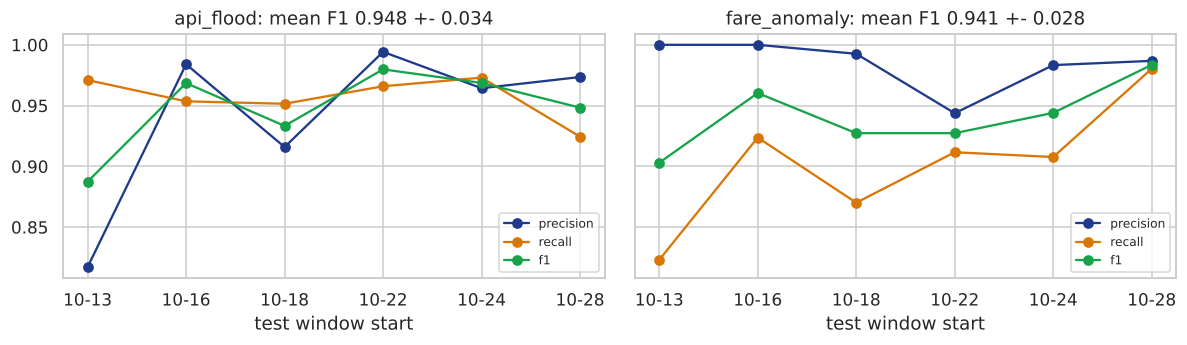

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for a, (name, e) in zip(ax, DG["detectors"].items()):
    ro = e["data"]["rolling_origin"]["folds"]; x = [r["test_starts"][5:10] for r in ro]
    for k, c in [("precision", "#1E3A8A"), ("recall", "#D97706"), ("f1", "#16A34A")]: a.plot(x, [r[k] for r in ro], "o-", color=c, label=k)
    a.set_title(f"{name}: mean F1 {e['data']['rolling_origin']['f1']['mean']:.3f} +- {e['data']['rolling_origin']['f1']['sd']:.3f}"); a.set_xlabel("test window start"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Brand-new datasets (5 seeds, models never refitted)

                  F1 mean   F1 sd  F1 min  F1 max
cloned_tag         0.9677  0.0034  0.9652  0.9733
class_mismatch     1.0000  0.0000  1.0000  1.0000
duplicate_charge   1.0000  0.0000  1.0000  1.0000
fare_anomaly       0.9685  0.0033  0.9648  0.9733
api_flood          0.9618  0.0043  0.9567  0.9664


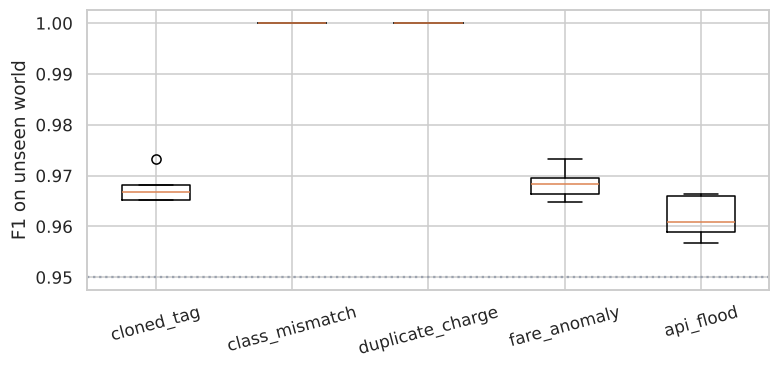

In [10]:
fw = DG["fresh_worlds"]; print(pd.DataFrame({k: {"F1 mean": v["f1"]["mean"], "F1 sd": v["f1"]["sd"], "F1 min": v["f1"]["min"], "F1 max": v["f1"]["max"]} for k, v in fw["summary"].items()}).T)
fig, ax = plt.subplots(figsize=(8, 3.3)); names = list(fw["summary"])
ax.boxplot([fw["summary"][n]["f1"]["values"] for n in names]); ax.set_xticklabels(names); ax.axhline(0.95, color="#9CA3AF", ls=":"); ax.set_ylabel("F1 on unseen world"); plt.xticks(rotation=15); plt.show()

## Positive controls: can the checks fail?
A memoriser that only knows *when and where* anomalies happened must be flagged **overfit**; a model starved of informative features must be flagged **underfit**.

In [11]:
pd.DataFrame([{"detector": n, "control": k, "train PR-AUC": c["train"]["pr_auc"], "test PR-AUC": c["test"]["pr_auc"], "verdict": c["verdict"], "expected": c["expected"], "caught": c["detected"]} for n, cs in DG["controls"].items() for k, c in cs.items()])

,detector,control,train PR-AUC,test PR-AUC,verdict,expected,caught
0,api_flood,overfit_control,0.8496,0.0259,overfit,overfit,True
1,api_flood,underfit_control,0.8918,0.8929,underfit,underfit,True
2,fare_anomaly,overfit_control,0.1720,0.0316,overfit,overfit,True
3,fare_anomaly,underfit_control,0.9552,0.9272,underfit,underfit,True


# Error analysis: where does it still go wrong?

## Fare: recall by billing ratio
Mild deviations that land *between* legitimate levels are the weak spot.

In [12]:
spec = specs["fare_anomaly"]; model, iso = joblib.load(spec["model_path"]), calib["calibrators"]["fare_anomaly"]; pr = C.predict(spec, model, iso, test); F = pr["X"]
t = test.assign(ratio=F.fare_ratio.to_numpy(), caught=pr["flagged"]); t = t[t.anomaly_type == "fare_tampering"]
print(t.groupby(pd.cut(t.ratio, [-.01, .01, .4, .7, .95, 1.2, 1.5, 3.1]), observed=True).caught.agg(recall="mean", n="size").round(3))

               recall   n
ratio                    
(-0.01, 0.01]   1.000  47
(0.01, 0.4]     1.000  73
(0.4, 0.7]      0.769  13
(0.7, 0.95]     0.548  31
(0.95, 1.2]     0.778  18
(1.2, 1.5]      1.000  54
(1.5, 3.1]      0.978  46


## Flood: where are the false positives?
A natural guess is that false positives sit next to real bursts (rows whose plaza context is flooded). The data says otherwise: they are **far from any real flood** (hundreds to thousands of rows away). They are isolated, short, benign load surges (2-3 consecutive high-load rows) that look like the start of a flood to a 5-row context window. Telling them apart would need either a longer window (which delays and blurs short real floods) or extra signals such as the source IP, which the model deliberately does not use.

In [13]:
spec = specs["api_flood"]; model, iso = joblib.load(spec["model_path"]), calib["calibrators"]["api_flood"]; pr = C.predict(spec, model, iso, test)
y = C.labels(test, spec); fp = np.flatnonzero(pr["flagged"] & ~y); tt = test.reset_index(drop=True); isf = (tt.anomaly_type == "api_flood").to_numpy()
near = []
for i in fp:
    same = np.flatnonzero(isf & (tt.plaza_id == tt.plaza_id[i]).to_numpy()); near.append(np.abs(same - i).min() if len(same) else 999)
print(f"{len(fp)} false positives; rows to the nearest real flood row at the same plaza (index distance): {sorted(near)}")
print("their own load vs plaza context:", tt.loc[fp, ["req_per_min"]].assign(ctx=np.expm1(pr["X"].ctx_req.to_numpy()[fp]).round(0)).describe().loc[["min", "50%", "max"]].round(0).to_dict())

7 false positives; rows to the nearest real flood row at the same plaza (index distance): [np.int64(695), np.int64(699), np.int64(718), 999, np.int64(2516), np.int64(2543), np.int64(2558)]
their own load vs plaza context: {'req_per_min': {'min': 512.0, '50%': 640.0, 'max': 824.0}, 'ctx': {'min': 469.0, '50%': 512.0, 'max': 552.0}}


## Cloned tag: ambiguous pairs
When a tag has only a lone impossible pair and no usable history, the data cannot say which passage is the clone, so both are flagged and marked ambiguous (about half correct, as expected).

In [14]:
for k, v in M["rule_detail"].items(): print(k, v)

cloned_tag {'flagged': 917, 'true_positives': 917, 'precision': 1.0}
cloned_tag_ambiguous {'flagged': 166, 'true_positives': 83, 'precision': 0.5}
cloned_tag_tag_level {'flagged': 816, 'labelled': 816, 'true_positives': 816, 'precision': 1.0, 'recall': 1.0}


## Summary
See the verdict table above. In short: the selected Isolation Forests show no train/test gap, learn the pattern with a fraction of the data, sit on the plateau of their capacity curves, beat every simple rule, are stable across time windows and across brand-new datasets, and are well calibrated. The checks were shown capable of failing. Remaining limitations: the data is synthetic and from one generator, mild under-charges between legitimate billing levels are the fare model's weak spot, and the rule detectors' scores are close to definitional.